In [28]:
!mkdir -p ~/.kaggle

In [29]:
!cp kaggle.json ~/.kaggle/

In [30]:
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:

#!kaggle datasets download -d tangpy/dogs-vs-cats

In [ ]:
import zipfile
zip_ref = zipfile.ZipFile('//content/drive/MyDrive/CampusX/100 Days of DL/Transfer Learning/archive.zip', 'r')
zip_ref.extractall('/content/drive/MyDrive/CampusX/100 Days of DL/Transfer Learning/')
zip_ref.close()

In [31]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Flatten
from keras.applications.vgg16 import VGG16

In [32]:
conv_base = VGG16(
    weights='imagenet',
    include_top = False,
    input_shape=(150,150,3)
)

In [33]:
conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 150, 150, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 150, 150, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 75, 75, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [34]:
model = Sequential()

model.add(conv_base)
model.add(Flatten())
model.add(Dense(256,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

In [35]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,812,353 (64.13 MB)

 Trainable params: 16,812,353 (64.13 MB)

 Non-trainable params: 0 (0.00 B)

In [36]:
conv_base.trainable = False

In [37]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,812,353 (64.13 MB)

 Trainable params: 2,097,665 (8.00 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [52]:
# Recreate train_ds and validation_ds using the new function to filter problematic images
train_dir = '/content/drive/MyDrive/CampusX/100 Days of DL/CNNs/archive/dogs-vs-cats-classification/train'
validation_dir = '/content/drive/MyDrive/CampusX/100 Days of DL/CNNs/archive/dogs-vs-cats-classification/validation'

print("Creating filtered training dataset...")
train_ds = create_filtered_image_dataset(
    directory=train_dir,
    image_size=(150, 150),
    batch_size=32,
    shuffle=True,
    seed=42
)

print("Creating filtered validation dataset...")
validation_ds = create_filtered_image_dataset(
    directory=validation_dir,
    image_size=(150, 150),
    batch_size=32,
    shuffle=False  # Typically no need to shuffle validation data
)

print("Filtered datasets created. You can now try running model.fit again.")


Creating filtered training dataset...
Creating filtered validation dataset...
Filtered datasets created. You can now try running model.fit again.


In [58]:
import tensorflow as tf
import os

def create_filtered_image_dataset(
    directory,
    image_size=(150, 150),
    batch_size=32,
    shuffle=True,
    seed=None
):
    """
    Creates a tf.data.Dataset from a directory, pre-filtering out images that cause
    InvalidArgumentError during decoding (e.g., 2-channel images) before dataset creation.
    It also includes robust error handling within the tf.data pipeline itself.
    """
    all_image_paths = []
    all_labels = []
    class_names = sorted([name for name in os.listdir(directory) if os.path.isdir(os.path.join(directory, name))])
    class_to_label = {class_name: i for i, class_name in enumerate(class_names)}

    print(f"Collecting and pre-filtering files from {directory} with classes: {class_names}")

    # Step 1: Collect all image paths and their labels
    for class_name in class_names:
        class_dir = os.path.join(directory, class_name)
        for fname in os.listdir(class_dir):
            fpath = os.path.join(class_dir, fname)
            if tf.io.gfile.isdir(fpath):
                continue
            all_image_paths.append(fpath)
            all_labels.append(class_to_label[class_name])

    # Step 2: Pre-filter problematic images by attempting to decode them outside the tf.data graph
    # This catches many errors early and provides immediate feedback.
    filtered_image_paths = []
    filtered_labels = []
    skipped_count = 0

    for i, image_path in enumerate(all_image_paths):
        try:
            img_bytes = tf.io.read_file(image_path)
            # Attempt to decode to 3 channels to check validity.
            # This will raise InvalidArgumentError for 2-channel images, corrupted headers, etc.
            _ = tf.image.decode_image(img_bytes, channels=3, expand_animations=False)
            filtered_image_paths.append(image_path)
            filtered_labels.append(all_labels[i])
        except (tf.errors.InvalidArgumentError, Exception) as e:
            skipped_count += 1
            print(f"Pre-filtering: Skipping problematic image: {image_path} - Error: {e}")

    print(f"Finished pre-filtering. Total images found: {len(all_image_paths)}, Skipped: {skipped_count}, Remaining: {len(filtered_image_paths)}")

    if not filtered_image_paths:
        raise ValueError(f"No valid images found in directory: {directory} after filtering.")

    # Convert to TensorFlow tensors
    image_paths_tensor = tf.constant(filtered_image_paths)
    labels_tensor = tf.constant(filtered_labels)

    # Step 3: Create the TF Data pipeline from the pre-filtered list with robust error handling in map function
    def _load_and_preprocess_image_map_fn(image_path, label):
        def _decode_and_preprocess(image_path_str, label_val):
            try:
                img_bytes = tf.io.read_file(image_path_str)
                img = tf.image.decode_image(img_bytes, channels=3, expand_animations=False)
                img = tf.image.resize(img, image_size)
                img = tf.cast(img / 255.0, tf.float32)  # Normalize
                img.set_shape([image_size[0], image_size[1], 3]) # Ensure fixed shape
                return img, label_val
            except tf.errors.InvalidArgumentError as e:
                # Return a 'bad' indicator for images that failed decoding in the graph
                print(f"tf.data.map: Skipping problematic image: {image_path_str.decode()} - Error: {e}")
                return tf.constant(0.0, shape=(image_size[0], image_size[1], 3), dtype=tf.float32), tf.constant(-1, dtype=tf.int32)
            except Exception as e:
                print(f"tf.data.map: Skipping image due to general error: {image_path_str.decode()} - Error: {e}")
                return tf.constant(0.0, shape=(image_size[0], image_size[1], 3), dtype=tf.float32), tf.constant(-1, dtype=tf.int32)

        # Wrap the Python function with tf.py_function to handle errors gracefully within the graph
        image, label = tf.py_function(
            _decode_and_preprocess,
            [image_path, label],
            [tf.float32, tf.int32]
        )
        # Set shapes after py_function, as py_function loses shape information
        image.set_shape([image_size[0], image_size[1], 3])
        label.set_shape([]) # Label is a scalar

        return image, label

    dataset = tf.data.Dataset.from_tensor_slices((image_paths_tensor, labels_tensor))

    if shuffle:
        dataset = dataset.shuffle(buffer_size=len(filtered_image_paths), seed=seed)

    dataset = dataset.map(_load_and_preprocess_image_map_fn, num_parallel_calls=tf.data.AUTOTUNE)

    # Filter out images that returned the 'bad' label (-1) from the map function
    dataset = dataset.filter(lambda image, label: tf.not_equal(label, -1))

    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(buffer_size=tf.data.AUTOTUNE)

    return dataset

In [54]:
# The normalization step is now included in the `create_filtered_image_dataset` function,
# so this cell is no longer needed.
# If you still want to apply further transformations, you can do so here.
# For now, this cell will be cleared.


In [55]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [56]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [59]:
history = model.fit(train_ds,epochs=10,validation_data=validation_ds)

Epoch 1/10
      2/Unknown 5s 2s/step - accuracy: 0.9062 - loss: 0.1897

KeyboardInterrupt: 

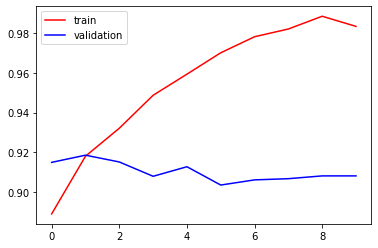

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue',label='validation')
plt.legend()
plt.show()

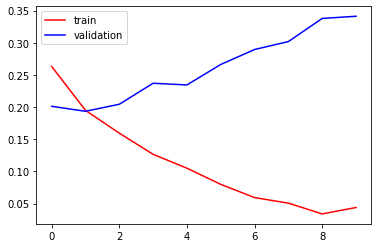

In [ ]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue',label='validation')
plt.legend()
plt.show()